In [1]:
# Import Libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, models,layers

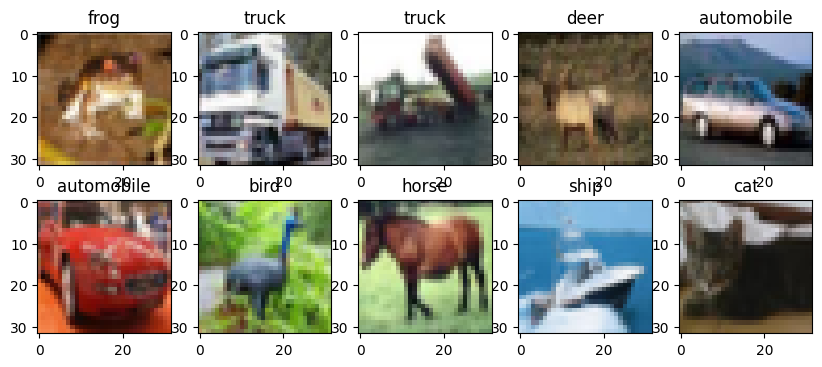

In [2]:
# Load CIFAR-10 Dataset
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

#train_images → 50,000 training images
#train_labels → 50,000 training labels (0 to 9)
#test_images → 10,000 test images
#test_labels → 10,000 test labels

# Normalize pixel values between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

#train_images / 255.0 → Converts pixel values from 0-255 to 0-1.
#test_images / 255.0 → Same for test images.
#255.0 → Total possible pixel value (8-bit image).

# Class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 
               'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Show few sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(train_images[i])
    plt.title(class_names[train_labels[i][0]])
    #class_names[train_labels[i][0]] → Convert numeric label to text.
    #[i][0] → Since label shape is (50000, 1), we access its value.
plt.show()

In [3]:
# Build CNN Model
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.Flatten(),

    layers.Dense(64, activation='relu'),
    layers.Dense(10)  # Output layer (10 classes)
])

c:\Users\<user>\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [4]:
# Compile Model
model.compile(optimizer='adam', # Optimizer algorithm (auto-adjusts weights).
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

# Train Model
history = model.fit(train_images, train_labels, epochs=5, 
                    validation_data=(test_images, test_labels))

# Evaluate Model
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print("\nTest accuracy:", test_acc)

Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 26s 15ms/step - accuracy: 0.4459 - loss: 1.5181 - val_accuracy: 0.5475 - val_loss: 1.2292
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 39s 14ms/step - accuracy: 0.5954 - loss: 1.1372 - val_accuracy: 0.6243 - val_loss: 1.0705
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 16ms/step - accuracy: 0.6522 - loss: 0.9846 - val_accuracy: 0.6526 - val_loss: 0.9822
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.6897 - loss: 0.8840 - val_accuracy: 0.6674 - val_loss: 0.9524
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 24s 16ms/step - accuracy: 0.7140 - loss: 0.8125 - val_accuracy: 0.6935 - val_loss: 0.8797
313/313 - 3s - 9ms/step - accuracy: 0.6935 - loss: 0.8797

Test accuracy: 0.6934999823570251


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


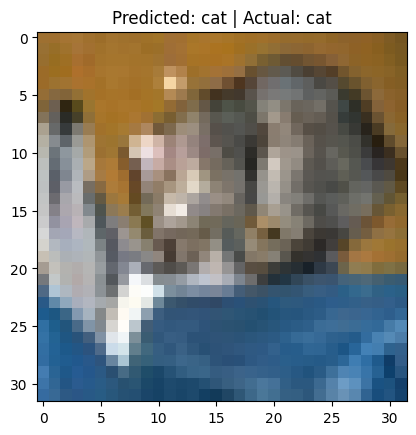

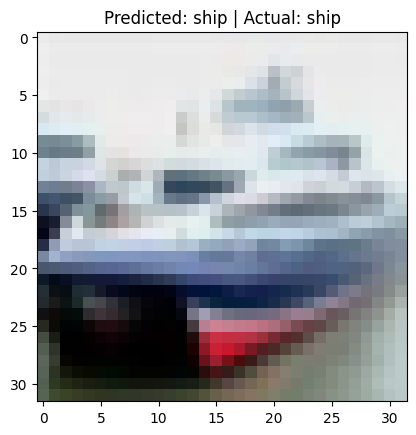

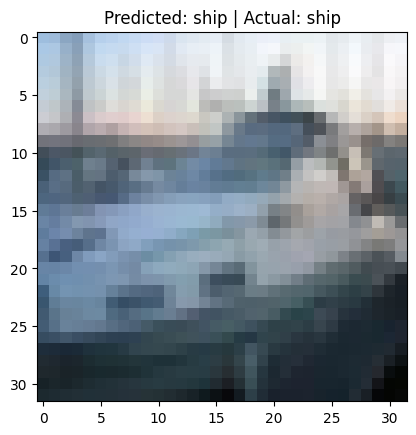

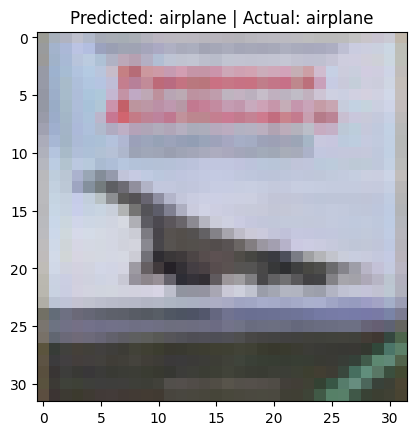

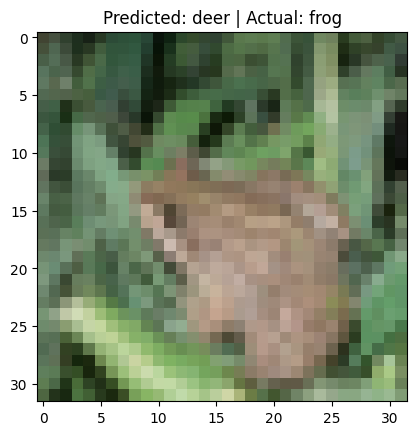

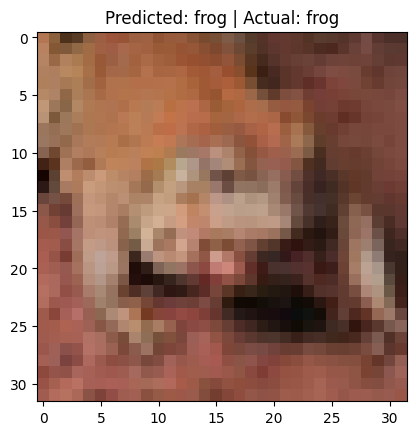

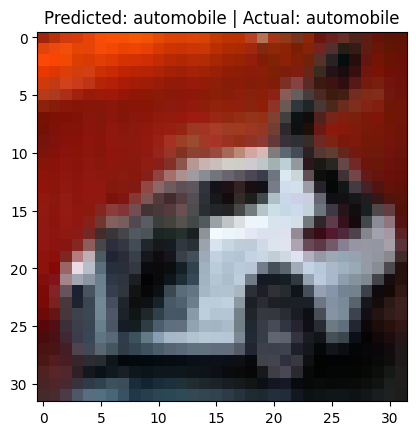

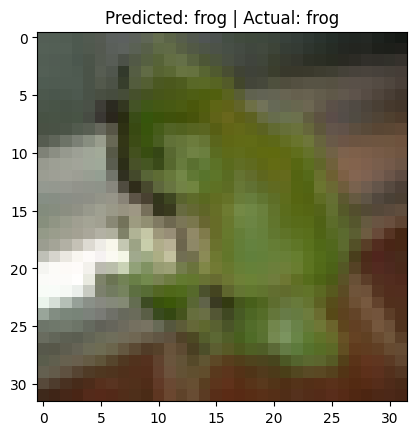

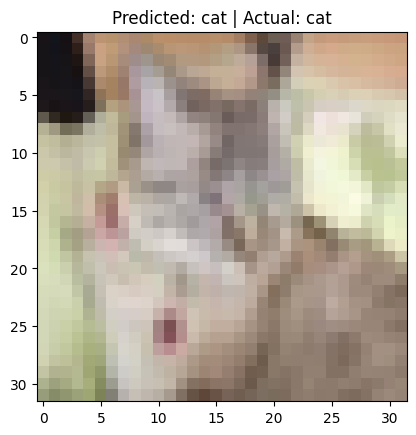

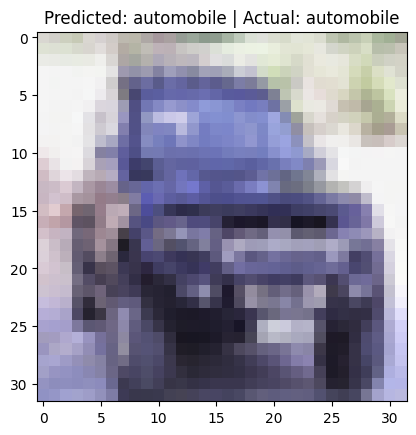

In [5]:
# Predicting few samples
probability_model = tf.keras.Sequential([model, tf.keras.layers.Softmax()])
predictions = probability_model.predict(test_images)

# Display predictions for 5 test images
for i in range(10):
    plt.imshow(test_images[i])
    plt.title("Predicted: {} | Actual: {}".format(
        class_names[np.argmax(predictions[i])],
        class_names[test_labels[i][0]]
    ))
    plt.show()